# 최종 전처리 명세 · 동결 결과 검토
**guardian_text_v2_final · Broad/Strict weekly**

추가 불용어는 **happened, latest, coverage, rolling, live, news** 여섯 개뿐이다.
`new`, `year`, `business`, `says`는 유지한다. 표제어화는 비활성화이다.
이 노트북은 저장된 결과만 읽으며 감성모델·WSI·FGI·시차·수익률 분석을 실행하지 않는다.

In [1]:
from pathlib import Path
import runpy,json
BASE=Path.cwd().resolve()
if not (BASE/"guardian_full_collection.py").exists():
    BASE=BASE/"midterm paper"
runpy.run_path(str(BASE/"guardian_full_collection.py"))
import pandas as pd
from IPython.display import display,Markdown,Image
RESULTS=BASE/"results/guardian_text_final"
pd.set_option("display.max_colwidth",100)
STRATEGY="broad_business_control"  # anchors_stock_market_tag로 변경 가능
policy=json.loads((BASE/"FINAL_PREPROCESSING_POLICY.json").read_text(encoding="utf-8"))
print(policy["status"],policy["version"])
print("Policy SHA-256:",policy["policy_sha256"])

FINAL_PREPROCESSING_SPECIFICATION guardian_text_v2_final
Policy SHA-256: 2874fd2b32c45097b161ccc62931a899777a0c7b9711d98efd587d7d1b1dff5d


## 1. Clean 토큰·고유 어휘 변경 전후
원자료와 v1 처리 자료는 보존했다. 삭제 수는 두 전략 각각 계산하므로 합집합에 더하지 않는다.

In [2]:
display(pd.read_csv(RESULTS/"custom_stopword_before_after.csv"))
display(pd.read_csv(RESULTS/"custom_stopword_removed_counts.csv"))

,query_strategy,articles,clean_tokens_before,clean_tokens_after,tokens_removed,removed_pct,unique_tokens_before,unique_tokens_after,new_top30_terms
0,broad_business_control,5054,112409,106612,5797,5.157060,12556,12550,hit | global | oil | up | record
1,anchors_stock_market_tag,2512,57888,53282,4606,7.956744,7338,7332,says | over | rate | year | oil


,query_strategy,term,before_count,after_count
0,broad_business_control,coverage,854,0
1,broad_business_control,happened,2101,0
2,broad_business_control,latest,859,0
3,broad_business_control,live,229,0
4,broad_business_control,news,915,0
5,broad_business_control,rolling,839,0
6,anchors_stock_market_tag,coverage,697,0
7,anchors_stock_market_tag,happened,1610,0
8,anchors_stock_market_tag,latest,701,0
9,anchors_stock_market_tag,live,153,0


## 2. Top 30 전후와 신규 진입
새 단어를 추가한 것이 아니라 여섯 단어 제외 후 기존 단어 순위가 올라간 결과이다.

In [3]:
before=pd.read_csv(RESULTS/"top30_before.csv")
after=pd.read_csv(RESULTS/"top30_after.csv")
paired=before.loc[before.query_strategy.eq(STRATEGY)].merge(after.loc[after.query_strategy.eq(STRATEGY)],on=["query_strategy","rank"],suffixes=("_before","_after"))
display(paired)
display(pd.read_csv(RESULTS/"top30_new_entries.csv"))

,query_strategy,rank,term_before,count_before,term_after,count_after,entered_top30
0,broad_business_control,1,happened,2101,uk,1686,False
1,broad_business_control,2,uk,1686,us,1633,False
2,broad_business_control,3,us,1633,financial,1098,False
3,broad_business_control,4,financial,1098,economic,1083,False
4,broad_business_control,5,economic,1083,markets,932,False
5,broad_business_control,6,markets,932,stock,653,False
6,broad_business_control,7,news,915,bank,633,False
7,broad_business_control,8,latest,859,says,631,False
8,broad_business_control,9,coverage,854,inflation,575,False
9,broad_business_control,10,rolling,839,over,518,False


,query_strategy,rank,term,count,entered_top30
0,broad_business_control,26,hit,414,True
1,broad_business_control,27,global,402,True
2,broad_business_control,28,oil,402,True
3,broad_business_control,29,up,400,True
4,broad_business_control,30,record,394,True
5,anchors_stock_market_tag,26,says,258,True
6,anchors_stock_market_tag,27,over,252,True
7,anchors_stock_market_tag,28,rate,251,True
8,anchors_stock_market_tag,29,year,245,True
9,anchors_stock_market_tag,30,oil,240,True


## 3. 금융 어휘와 잔여 상용구
경제 어휘의 빈도는 그대로 보존한다. 반복 템플릿에 남은 경제 단어도 추가 삭제 없이 보고한다.

In [4]:
financial=pd.read_csv(RESULTS/"financial_vocabulary_preservation.csv")
display(financial.loc[financial.query_strategy.eq(STRATEGY)])
display(pd.read_csv(RESULTS/"phrase_artifact_review.csv"))
display(pd.read_csv(RESULTS/"repeated_description_templates.csv"))
display(pd.read_csv(RESULTS/"common_bigrams.csv").loc[lambda t:t.query_strategy.eq(STRATEGY)].head(30))

,query_strategy,concept,term,before_count,after_count,status
0,broad_business_control,equities,stock,653,653,preserved
1,broad_business_control,equities,stocks,274,274,preserved
2,broad_business_control,equities,share,119,119,preserved
3,broad_business_control,equities,shares,446,446,preserved
4,broad_business_control,equities,equity,136,136,preserved
5,broad_business_control,equities,equities,8,8,preserved
6,broad_business_control,market,market,483,483,preserved
7,broad_business_control,market,markets,932,932,preserved
8,broad_business_control,Fed/Federal Reserve,fed,157,157,preserved
9,broad_business_control,Fed/Federal Reserve,federal,132,132,preserved


,query_strategy,phrase,source_sentiment_article_count,frequency_tokens_before,frequency_tokens_after,source_articles_retaining_residue,additional_phrase_deletion_applied
0,broad_business_control,as it happened,2096,happened,NaN,0,False
1,broad_business_control,live updates,0,live updates,updates,0,False
2,broad_business_control,sign up,1,sign up,sign up,1,False
3,broad_business_control,read more,0,read more,read more,0,False
4,broad_business_control,subscribe,0,subscribe,subscribe,0,False
5,broad_business_control,the guardian,8,guardian,guardian,5,False
6,broad_business_control,follow the latest,0,follow latest,follow,0,False
7,broad_business_control,rolling coverage,801,rolling coverage,NaN,0,False
8,broad_business_control,economic and financial,833,economic financial,economic financial,833,False
9,broad_business_control,financial and economic,1,financial economic,financial economic,1,False


,query_strategy,description_visible,identical_description_articles,text_clean_before,text_clean_after,additional_deletion_applied
0,broad_business_control,Rolling coverage of the latest economic and financial news,418,rolling coverage latest economic financial news,economic financial,False
1,broad_business_control,"Each month we look at key indicators to see what effect the Brexit process has on growth, prospe...",5,month look key indicators see effect brexit process growth prosperity trade,month look key indicators see effect brexit process growth prosperity trade,False
2,broad_business_control,"Each month we look at key indicators to see what effect the Brexit process has had on growth, pr...",5,month look key indicators see effect brexit process growth prosperity trade,month look key indicators see effect brexit process growth prosperity trade,False
3,broad_business_control,"Rolling live coverage of business, economics and financial markets",4,rolling live coverage business economics financial markets,business economics financial markets,False
4,anchors_stock_market_tag,Rolling coverage of the latest economic and financial news,381,rolling coverage latest economic financial news,economic financial,False


,query_strategy,rank,bigram,count,document_count
0,broad_business_control,1,wall street,263,261
1,broad_business_control,2,interest rates,259,235
2,broad_business_control,3,stock markets,237,231
3,broad_business_control,4,stock market,220,214
4,broad_business_control,5,interest rate,166,160
5,broad_business_control,6,trade war,159,150
6,broad_business_control,7,record high,142,138
7,broad_business_control,8,day's economic,135,135
8,broad_business_control,9,central bank,133,130
9,broad_business_control,10,uk economy,120,108


## 4. 전체 기간과 대표 연도 워드클라우드
2017·2020·2026 패널과 모든 연도의 개별 결과를 저장했다. 2026년은 10월 25일까지이다.

**broad · full period**

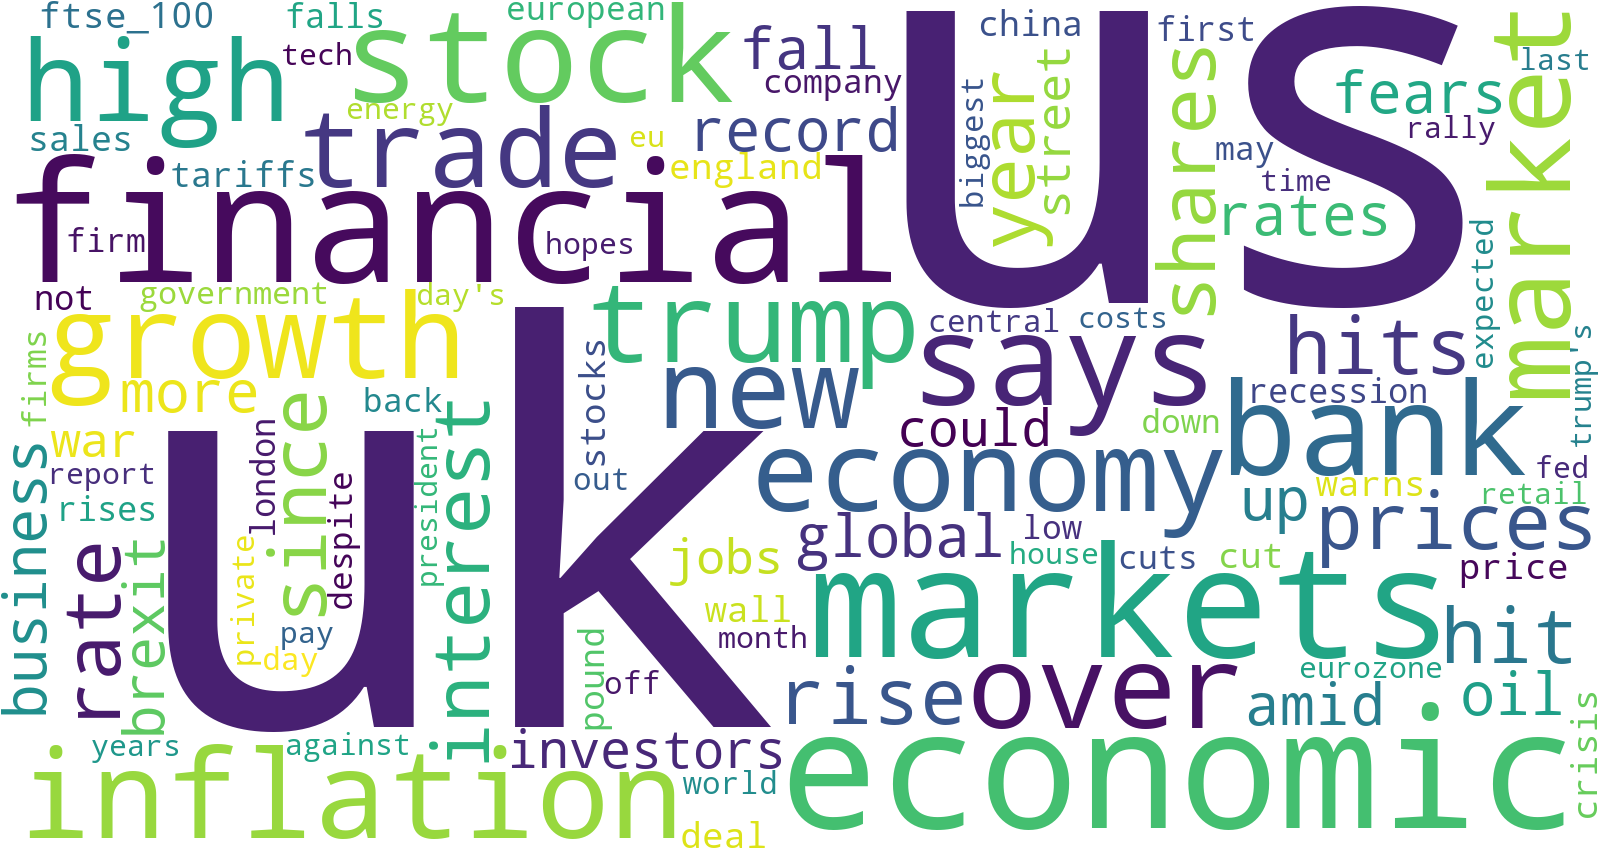

**strict · full period**

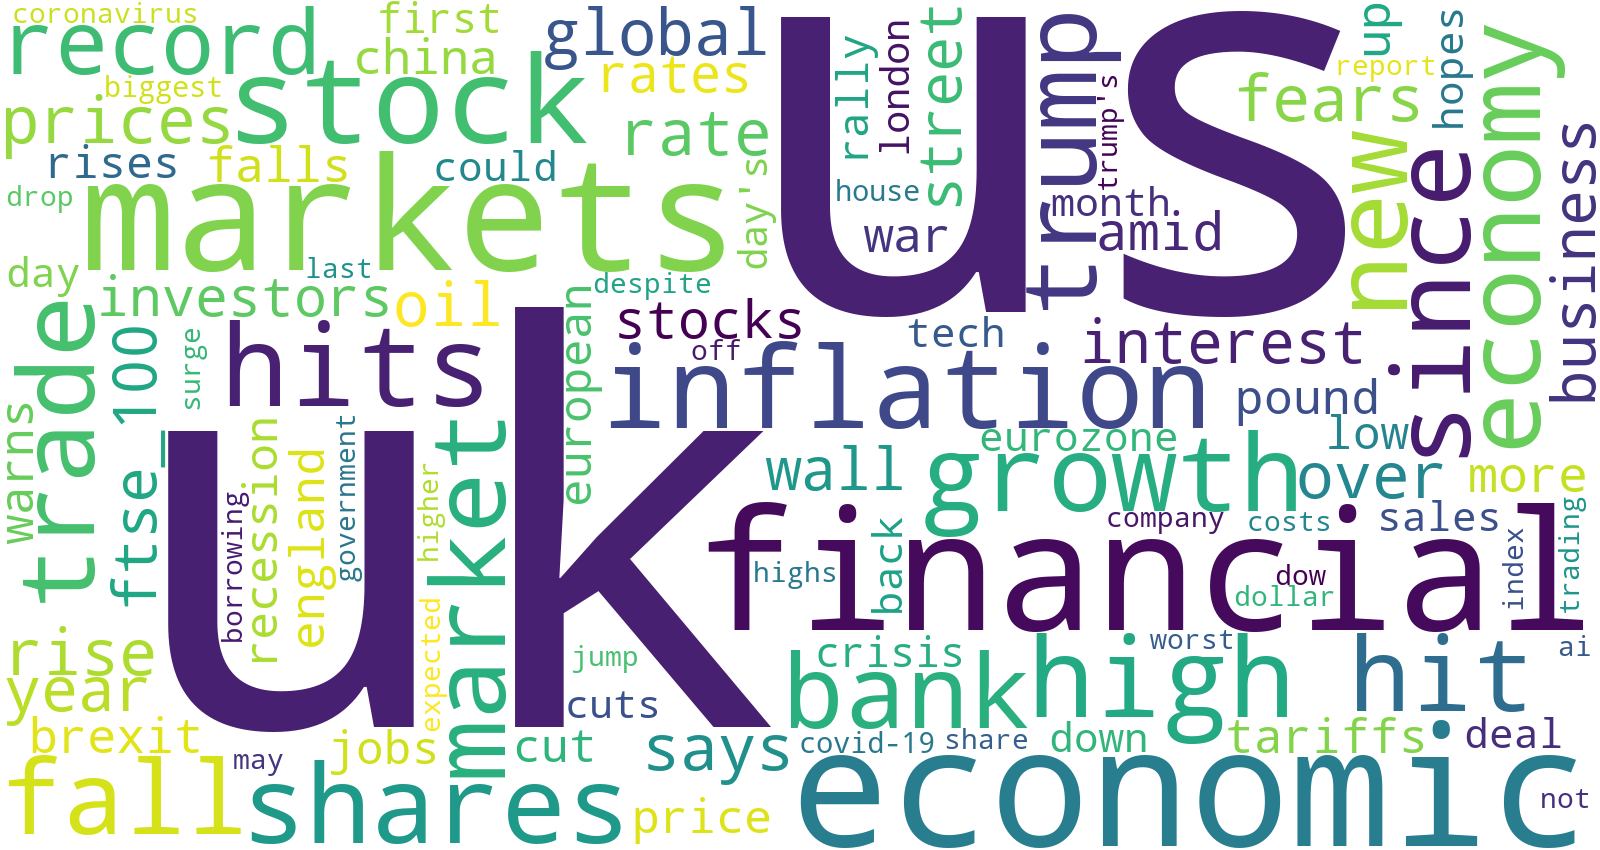

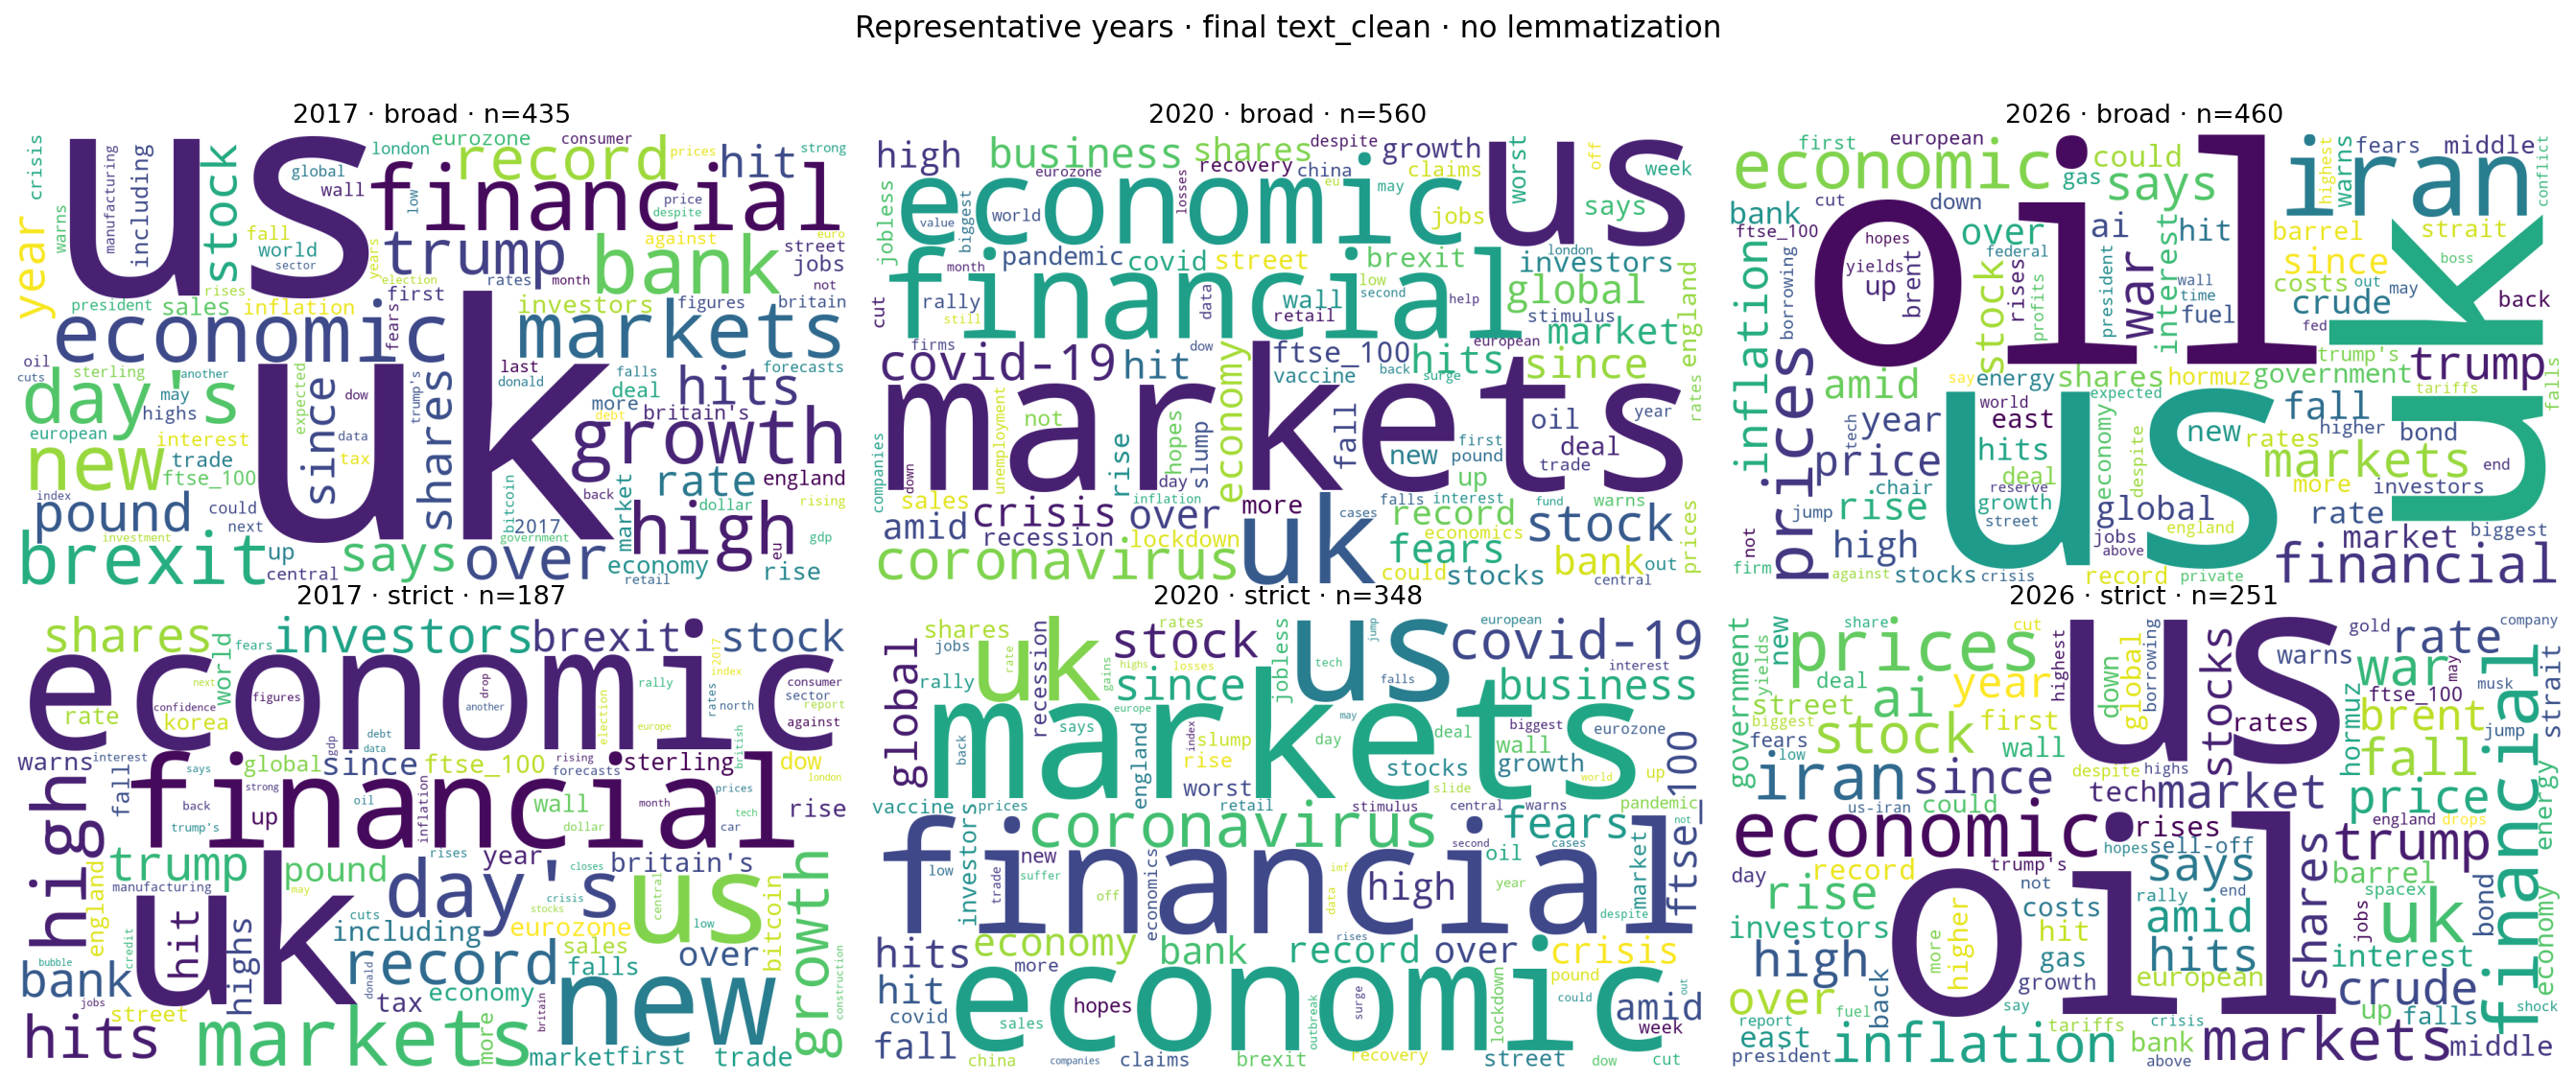

,query_strategy,year,rank,term,count,document_count
0,broad_business_control,2017,1,uk,151,122
1,broad_business_control,2017,2,us,119,97
2,broad_business_control,2017,3,financial,93,92
3,broad_business_control,2017,4,economic,83,80
4,broad_business_control,2017,5,bank,76,60
5,broad_business_control,2017,6,growth,74,59
6,broad_business_control,2017,7,markets,74,67
7,broad_business_control,2017,8,new,74,71
8,broad_business_control,2017,9,day's,67,67
9,broad_business_control,2017,10,brexit,62,53


In [5]:
for label in ["broad","strict"]:
    display(Markdown(f"**{label} · full period**"))
    display(Image(filename=str(BASE/f"figures/guardian_text_final/wordcloud_{label}_full_period.png"),width=1100))
display(Image(filename=str(BASE/"figures/guardian_text_final/wordcloud_representative_years.png"),width=1300))
display(pd.read_csv(RESULTS/"representative_year_word_frequencies.csv").loc[lambda t:t.query_strategy.eq(STRATEGY)].groupby("year").head(10))

## 5. 최종 Parquet·주간 기술통계·검증
text_raw/text_sentiment는 v1과 동일하다. 기사 수와 주간 구조도 그대로 두고 clean 토큰 통계만 갱신했다.

In [6]:
display(pd.read_csv(RESULTS/"custom_stopword_inspection.csv").head(6))
display(pd.read_csv(RESULTS/"weekly_article_token_counts.csv").loc[lambda t:t.query_strategy.eq(STRATEGY)].head(12))
print((RESULTS/"independent_validation.json").read_text(encoding="utf-8"))
display(Markdown((BASE/"FINAL_PREPROCESSING_REVIEW.md").read_text(encoding="utf-8")))

,guardian_id,year,text_raw,text_sentiment,text_clean_before,text_clean_after
0,business/2017/jan/03/stock-markets-share-tips-guardian-2017-political-certainty-earners,2017,Stock markets: the Guardian's share tips for 2017\nAfter the political shocks of 2016 resulted i...,Stock markets: the Guardian's share tips for 2017 After the political shocks of 2016 resulted in...,stock markets guardian's share tips 2017 political shocks 2016 resulted surprise price boost tea...,stock markets guardian's share tips 2017 political shocks 2016 resulted surprise price boost tea...
1,business/blog/live/2017/jan/03/markets-wait-for-uk-manufacturing-data-ftse-100-business-live,2017,UK manufacturing PMI rises to two-year high as FTSE 100 hits fresh record – as it happened\nSter...,UK manufacturing PMI rises to two-year high as FTSE 100 hits fresh record – as it happened Sterl...,uk manufacturing pmi rises two-year high ftse_100 hits fresh record happened sterling rises two-...,uk manufacturing pmi rises two-year high ftse_100 hits fresh record sterling rises two-week high...
2,business/live/2017/jan/04/ftse-bids-for-new-record-but-next-sales-disappoint-business-live,2017,UK construction sector grows but Next disappoints - as it happened\nThe UK construction sector g...,UK construction sector grows but Next disappoints - as it happened The UK construction sector gr...,uk construction sector grows next disappoints happened uk construction sector grew decent pace d...,uk construction sector grows next disappoints uk construction sector grew decent pace december a...
3,business/2018/jan/02/the-guardians-share-tips-for-2018,2018,The Guardian's share tips for 2018\nGlobal stock markets hitting record high bodes well for inve...,The Guardian's share tips for 2018 Global stock markets hitting record high bodes well for inves...,guardian's share tips 2018 global stock markets hitting record high bodes well investors present...,guardian's share tips 2018 global stock markets hitting record high bodes well investors present...
4,business/2018/jan/02/marks-spencer-sells-hong-kong-macau-al-futtaim,2018,Marks & Spencer sells Hong Kong stores as it retreats from overseas markets\nSale of 27 stores i...,Marks & Spencer sells Hong Kong stores as it retreats from overseas markets Sale of 27 stores in...,marks spencer sells hong kong stores retreats overseas markets sale 27 stores hong kong macau al...,marks spencer sells hong kong stores retreats overseas markets sale 27 stores hong kong macau al...
5,business/2018/jan/02/trump-tax-cut-to-dent-bp-profits-by-15bn,2018,"Trump tax cut to dent BP profits by $1.5bn, company warns\nOil firm joins Goldman Sachs and Shel...","Trump tax cut to dent BP profits by $1.5bn, company warns Oil firm joins Goldman Sachs and Shell...",trump tax cut dent bp profits $1.5bn company warns oil firm joins goldman sachs shell declaring ...,trump tax cut dent bp profits $1.5bn company warns oil firm joins goldman sachs shell declaring ...


,query_strategy,week_id,week_start,week_end,days_observed,is_complete_week,article_count,token_count,unique_token_count,token_representation
0,broad_business_control,2016-W52,2016-12-26,2017-01-01,1,False,0,0,0,tokens_clean
1,broad_business_control,2017-W01,2017-01-02,2017-01-08,7,True,5,107,84,tokens_clean
2,broad_business_control,2017-W02,2017-01-09,2017-01-15,7,True,8,182,136,tokens_clean
3,broad_business_control,2017-W03,2017-01-16,2017-01-22,7,True,14,316,244,tokens_clean
4,broad_business_control,2017-W04,2017-01-23,2017-01-29,7,True,10,207,156,tokens_clean
5,broad_business_control,2017-W05,2017-01-30,2017-02-05,7,True,7,163,138,tokens_clean
6,broad_business_control,2017-W06,2017-02-06,2017-02-12,7,True,8,176,137,tokens_clean
7,broad_business_control,2017-W07,2017-02-13,2017-02-19,7,True,10,223,174,tokens_clean
8,broad_business_control,2017-W08,2017-02-20,2017-02-26,7,True,7,143,123,tokens_clean
9,broad_business_control,2017-W09,2017-02-27,2017-03-05,7,True,11,235,197,tokens_clean


{
  "status": "passed",
  "records_verified": 5265,
  "all_non_clean_fields_including_raw_and_sentiment_identical": true,
  "tokens_exactly_baseline_minus_six_approved_stopwords": true,
  "frequency_bigrams_and_weekly_counts_verified": true,
  "financial_terms_preserved": true,
  "final_policy_hash_verified": "2874fd2b32c45097b161ccc62931a899777a0c7b9711d98efd587d7d1b1dff5d",
  "wordclouds_verified": 25,
  "empty_final_clean_text": 0,
  "network_requests": 0,
  "sentiment_scoring": false
}


# 최종 전처리 검토 · 정책 동결

정책 버전: **guardian_text_v2_final**. 물리적 기사 **5,265건**.
text_raw·text_sentiment와 모든 원본 메타데이터/전략 플래그를 보존하고 text_clean 계열에서 승인된 여섯 단어만 제거했다.
추가 불용어: **happened, latest, coverage, rolling, live, news**.
**new, year, business, says는 추가하지 않았고 기존 출현 횟수도 그대로 보존했다. 표제어화는 비활성화했다.**

## 토큰 변경 전후

| 전략 | clean 토큰 전 | 후 | 제거 | 감소율 | 고유 어휘 전 | 후 |
|---|---:|---:|---:|---:|---:|---:|
| broad_business_control | 112,409 | 106,612 | 5,797 | 5.16% | 12,556 | 12,550 |
| anchors_stock_market_tag | 57,888 | 53,282 | 4,606 | 7.96% | 7,338 | 7,332 |

단어 빈도만 기준으로 여섯 항목을 제외했으며 나머지 모든 토큰의 출현 횟수는 동일하다.
이 결과는 빈도 입력의 변경 진단이며 실제 감성점수나 감성모델 성능 비교가 아니다.

## Top 30 신규 진입

- broad_business_control: hit (새 순위 26, 414회), global (새 순위 27, 402회), oil (새 순위 28, 402회), up (새 순위 29, 400회), record (새 순위 30, 394회)
- anchors_stock_market_tag: says (새 순위 26, 258회), over (새 순위 27, 252회), rate (새 순위 28, 251회), year (새 순위 29, 245회), oil (새 순위 30, 240회)

변경 전 top30_before.csv와 변경 후 top30_after.csv에는 전체 30개씩의 순위와 빈도가 있다.
새 단어를 삽입한 것이 아니라 기존 단어가 상위 30위로 올라온 것이다.

## 금융 어휘 보존

financial_vocabulary_preservation.csv에서 stock/stocks, share/shares, equities, market, Fed/Federal Reserve,
interest/rates, inflation, oil, tariffs/trade, banks, technology, s&p_500, Nasdaq, Dow 등을 확인했다.
원래 존재한 항목은 빈도가 그대로이며 없는 항목은 not_present; not_inserted로 기록했다.
검증은 단순 예시 목록에만 한정하지 않고 모든 비불용어 토큰의 빈도 동일성도 검사했다.

## 남아 있는 상용구 · 추가 규칙 미적용

원문과 text_sentiment는 보존하므로 해당 텍스트에서 상용구의 출현 횟수가 줄어들지는 않는다.
빈도 텍스트에서 as it happened의 happened와 rolling coverage 두 토큰은 제거되었다.
live updates에서는 live만 제거하며 updates는 추가 불용어로 승인되지 않아 남을 수 있다.
반복 설명 템플릿에 포함된 경제 어휘도 자동 삭제하지 않았다.

| 전략 | 같은 설명 템플릿 기사 수 | 삭제 후 남는 텍스트 |
|---|---:|---|
| broad_business_control | 418 | economic financial |
| anchors_stock_market_tag | 381 | economic financial |

이 템플릿의 economic/financial 빈도 잔류는 알려진 한계로 보고한다. 추가 단어/문구 삭제나 템플릿 제거는 하지 않았다.
bigrams는 원래 인접한 단어 중 둘 다 허용된 경우만 계산하므로 제거한 단어를 건너뛴 새 bigram은 만들지 않는다.
상용구별 원문 출현 수, 살아남는 토큰, 잔류 문서 수는 phrase_artifact_review.csv에 있다.
반복 설명의 원문과 전후 텍스트는 repeated_description_templates.csv에 있다.

## 최종 산출물

- data/processed/guardian_text_final/articles/year=YYYY/: 최종 Parquet; 원본 열 + 기존 text_raw/text_sentiment + 최종 text_clean.
- data/processed/guardian_text/articles/: 이전 v1 baseline. 덮어쓰지 않았다.
- results/guardian_text_final/: 전체/연도별 빈도, top100, bigrams, 대표 연도 표, 전후 비교, 주간 기술통계, 어휘 보존 점검.
- figures/guardian_text_final/: 연도별 20개, 전체 연도 패널 2개, broad/strict 전체 기간 2개, 대표 연도 패널 1개.
- 대표 연도는 2017·2020·2026이며 모든 연도 결과도 보존했다. 2026은 10월 25일까지의 부분 연도다.
- FINAL_PREPROCESSING_POLICY.json / .md: 최종 명세. 변경하려면 새 버전의 명시적 정책 수정이 필요하다.

## 검증과 중단 지점

5,265개 ID와 원본/이전 Parquet 해시, text_raw/text_sentiment 불변, 전략 소속, 비불용어 빈도 불변을 검증했다.
감성분석에 대한 불용어 적용은 없고, 표제어화·추가 문구 삭제도 없다.
VADER·WSI·FGI·시차·수익률 분석은 시작하지 않았다. 최종 어휘와 워드클라우드의 사용자 검토를 기다린다.
